In [1]:
!pip install tensorflow matplotlib seaborn pandas scikit-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.initializers import RandomNormal, GlorotNormal, HeNormal
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import Callback

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("Training Dataset:", X_train_full.shape)
print("Testing Dataset:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Dataset: (60000, 28, 28)
Testing Dataset: (10000, 28, 28)


In [4]:
# Normalize pixel values
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Split training and validation data
X_train = X_train_full[:50000]
y_train = y_train_full[:50000]

X_val = X_train_full[50000:]
y_val = y_train_full[50000:]

# Flatten images into 784 features
X_train = X_train.reshape(-1, 784)
X_val = X_val.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (50000, 784)
Validation: (10000, 784)
Testing: (10000, 784)


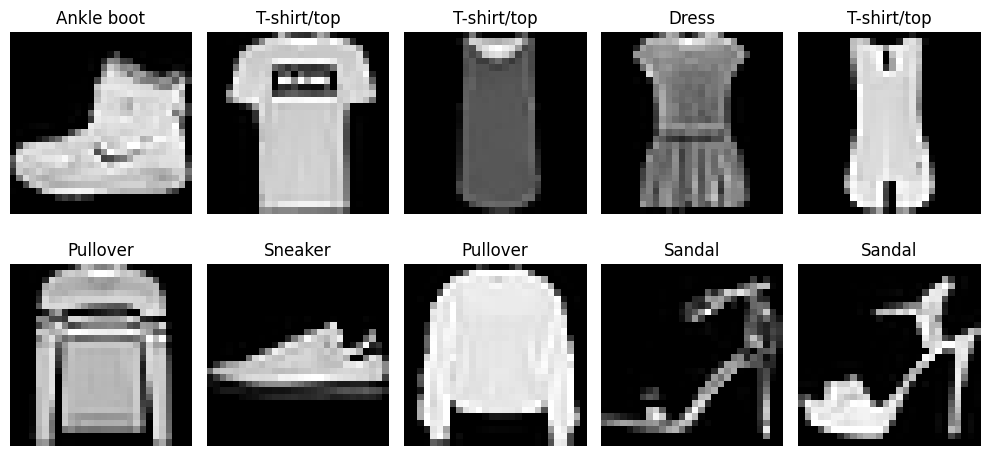

In [5]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover',
    'Dress', 'Coat', 'Sandal',
    'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
initializers = {
    "Small Random": RandomNormal(mean=0.0, stddev=0.01),
    "Xavier": GlorotNormal(),
    "He": HeNormal()
}

In [7]:
def build_model(initializer):

    model = Sequential()

    model.add(Input(shape=(784,)))

    for i in range(6):
        model.add(
            Dense(
                256,
                activation='relu',
                kernel_initializer=initializer
            )
        )

    model.add(
        Dense(
            10,
            activation='softmax'
        )
    )

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [8]:
class GradientMonitor(Callback):

    def __init__(self, X_sample, y_sample):
        super().__init__()

        self.X_sample = tf.convert_to_tensor(X_sample)
        self.y_sample = tf.convert_to_tensor(y_sample)

        self.gradient_history = []

    def on_epoch_end(self, epoch, logs=None):

        with tf.GradientTape() as tape:

            predictions = self.model(self.X_sample, training=True)

            loss = tf.keras.losses.sparse_categorical_crossentropy(
                self.y_sample,
                predictions
            )

            loss = tf.reduce_mean(loss)

        gradients = tape.gradient(
            loss,
            self.model.trainable_variables
        )

        layer_norms = []

        for layer in self.model.layers:

            if isinstance(layer, Dense):

                kernel = layer.kernel

                index = self.model.trainable_variables.index(kernel)

                grad = gradients[index]

                norm = tf.norm(grad).numpy()

                layer_norms.append(norm)

        self.gradient_history.append(layer_norms)

        print(
            f"\nEpoch {epoch + 1} Gradient Norms:",
            np.round(layer_norms, 6)
        )

In [9]:
class GradientMonitor(Callback):

    def __init__(self, X_sample, y_sample):
        super().__init__()
        self.X_sample = tf.convert_to_tensor(X_sample)
        self.y_sample = tf.convert_to_tensor(y_sample)
        self.gradient_history = []

    def on_epoch_end(self, epoch, logs=None):

        with tf.GradientTape() as tape:

            predictions = self.model(self.X_sample, training=True)

            loss = tf.reduce_mean(
                tf.keras.losses.sparse_categorical_crossentropy(
                    self.y_sample, predictions
                )
            )

        variables = self.model.trainable_variables
        gradients = tape.gradient(loss, variables)

        norms = []

        for layer in self.model.layers:
            if isinstance(layer, Dense):
                grad = gradients[variables.index(layer.kernel)] if False else None

                for variable, gradient in zip(variables, gradients):
                    if variable is layer.kernel:
                        grad = gradient
                        break

                norms.append(float(tf.norm(grad).numpy()))

        self.gradient_history.append(norms)

        print(
            f"Epoch {epoch + 1} Gradient Norms:",
            np.round(norms, 6)
        )

In [10]:
models = {}
histories = {}
gradient_monitors = {}
training_times = {}

for name, initializer in initializers.items():

    print("\n" + "=" * 50)
    print("Training using", name, "Initialization")
    print("=" * 50)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(initializer)

    monitor = GradientMonitor(
        X_train[:128],
        y_train[:128]
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        callbacks=[monitor],
        verbose=1
    )

    end_time = time.time()

    models[name] = model
    histories[name] = history
    gradient_monitors[name] = monitor

    training_times[name] = end_time - start_time

    print(
        name,
        "Training Time:",
        round(training_times[name], 2),
        "seconds"
    )


Training using Small Random Initialization
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3921 - loss: 1.4675Epoch 1 Gradient Norms: [1.303027 0.839683 1.111001 1.074914 1.067182 1.52393  1.642361]
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - accuracy: 0.5584 - loss: 1.0763 - val_accuracy: 0.7348 - val_loss: 0.7208
Epoch 2/10
381/391 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7202 - loss: 0.7272Epoch 2 Gradient Norms: [1.144968 0.48614  0.723072 0.695001 0.670203 1.096877 1.472497]
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7488 - loss: 0.6596 - val_accuracy: 0.7894 - val_loss: 0.5649
Epoch 3/10
384/391 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7904 - loss: 0.5430Epoch 3 Gradient Norms: [0.911086 0.349741 0.408879 0.438733 0.442252 0.591753 0.798561]
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7974 - loss: 0.5292 - val_accuracy: 0.8142 - val_loss: 0.4954
Epoch 4/10
387/391 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8180 - loss: 0.

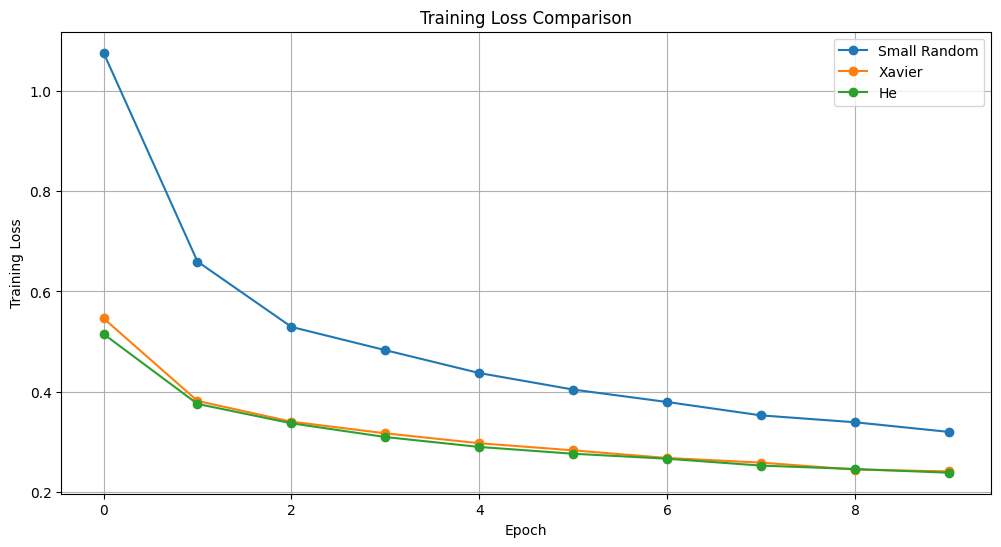

In [11]:
plt.figure(figsize=(12, 6))

for name in histories:

    plt.plot(
        histories[name].history['loss'],
        marker='o',
        label=name
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.legend()
plt.grid(True)
plt.show()

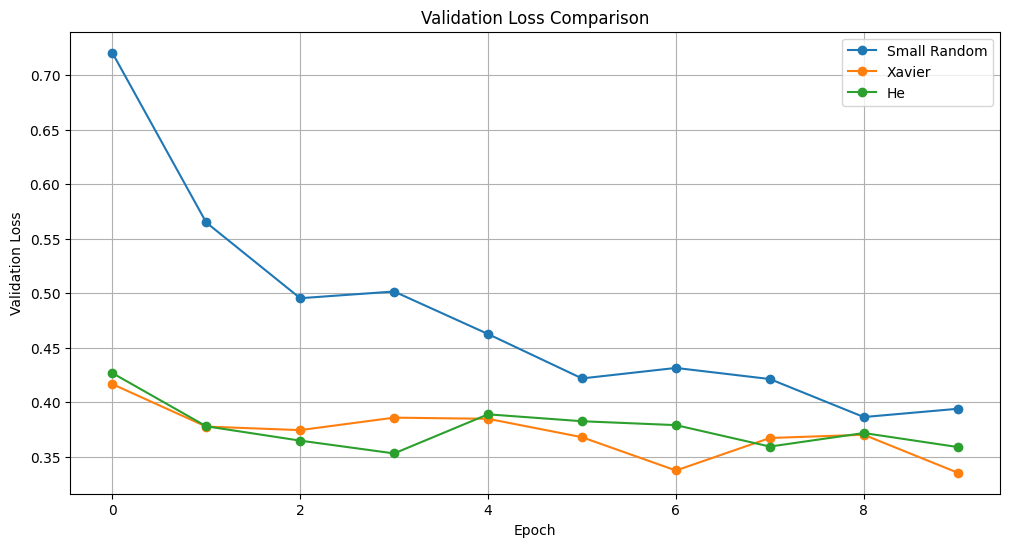

In [12]:
plt.figure(figsize=(12, 6))

for name in histories:

    plt.plot(
        histories[name].history['val_loss'],
        marker='o',
        label=name
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

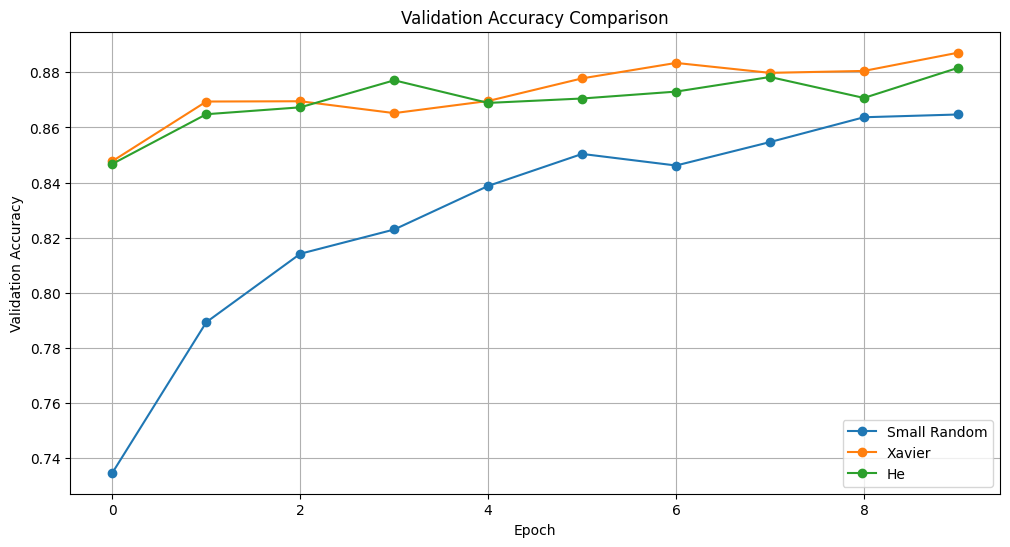

In [13]:
plt.figure(figsize=(12, 6))

for name in histories:

    plt.plot(
        histories[name].history['val_accuracy'],
        marker='o',
        label=name
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

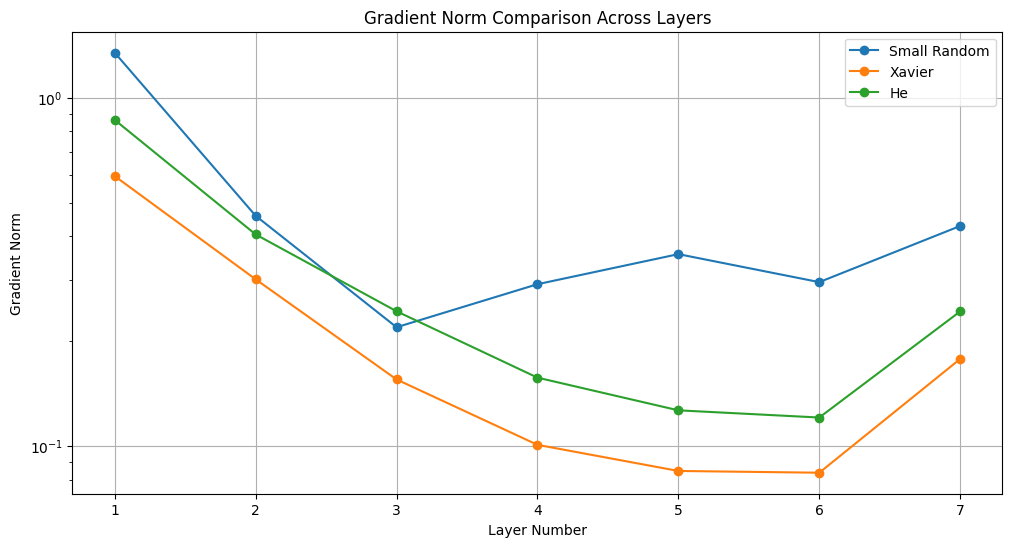

In [14]:
plt.figure(figsize=(12, 6))

for name in gradient_monitors:

    final_norms = gradient_monitors[name].gradient_history[-1]

    plt.plot(
        range(1, 8),
        final_norms,
        marker='o',
        label=name
    )

plt.title("Gradient Norm Comparison Across Layers")
plt.xlabel("Layer Number")
plt.ylabel("Gradient Norm")

plt.xticks(range(1, 8))
plt.yscale('log')

plt.legend()
plt.grid(True)
plt.show()

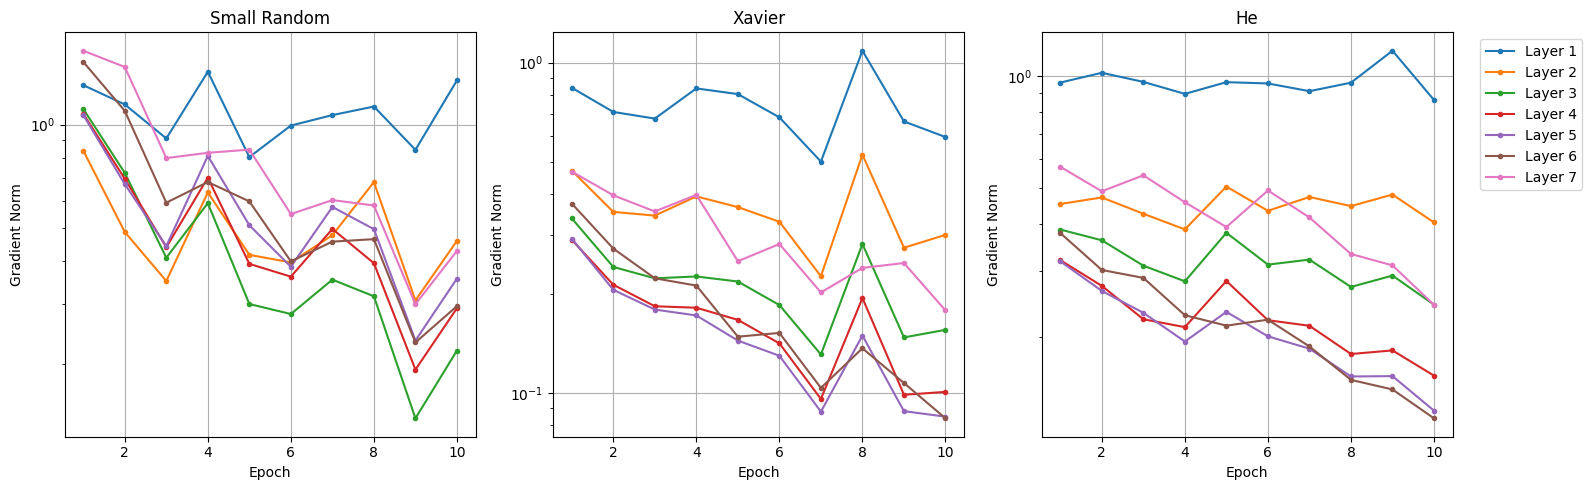

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, name in zip(axes, gradient_monitors):

    gradient_data = np.array(
        gradient_monitors[name].gradient_history
    )

    for layer in range(7):

        ax.plot(
            range(1, 11),
            gradient_data[:, layer],
            marker='.',
            label=f'Layer {layer + 1}'
        )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Gradient Norm")
    ax.set_yscale('log')
    ax.grid(True)

axes[-1].legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [16]:
results = []

for name, model in models.items():

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    results.append({
        "Initialization": name,
        "Training Loss": histories[name].history['loss'][-1],
        "Validation Loss": histories[name].history['val_loss'][-1],
        "Validation Accuracy": histories[name].history['val_accuracy'][-1] * 100,
        "Test Accuracy": test_accuracy * 100,
        "Training Time (seconds)": training_times[name]
    })

results_df = pd.DataFrame(results)

print("\nFINAL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))


FINAL PERFORMANCE COMPARISON
Initialization  Training Loss  Validation Loss  Validation Accuracy  Test Accuracy  Training Time (seconds)
  Small Random         0.3197           0.3938                86.47          85.62                  29.4217
        Xavier         0.2409           0.3351                88.71          87.92                  20.5137
            He         0.2383           0.3587                88.16          87.53                  21.3008


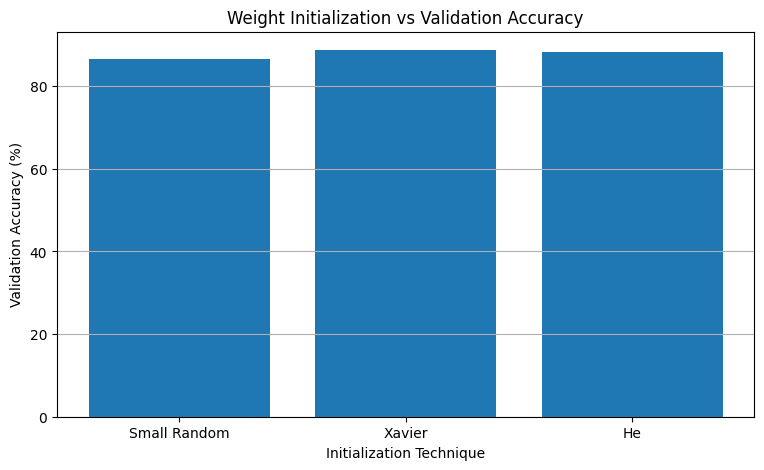

In [17]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df['Initialization'],
    results_df['Validation Accuracy']
)

plt.title("Weight Initialization vs Validation Accuracy")
plt.xlabel("Initialization Technique")
plt.ylabel("Validation Accuracy (%)")

plt.grid(axis='y')
plt.show()

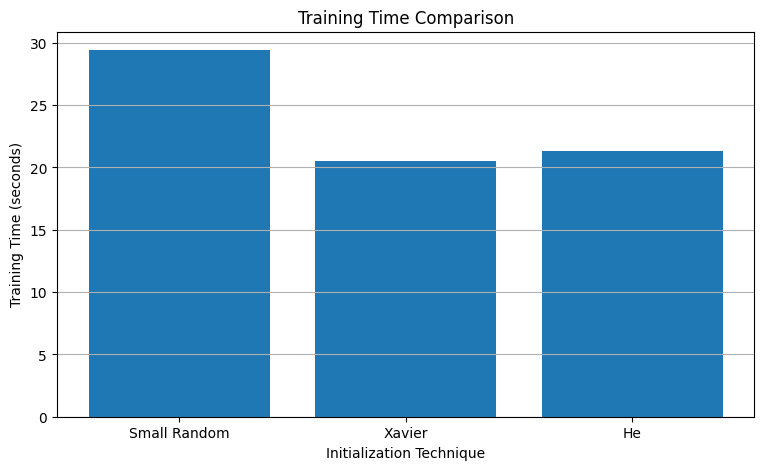

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df['Initialization'],
    results_df['Training Time (seconds)']
)

plt.title("Training Time Comparison")
plt.xlabel("Initialization Technique")
plt.ylabel("Training Time (seconds)")

plt.grid(axis='y')
plt.show()

In [19]:
best = results_df.loc[
    results_df['Validation Accuracy'].idxmax()
]

print("BEST WEIGHT INITIALIZATION")
print("--------------------------")

print("Method:", best['Initialization'])
print("Validation Accuracy:", round(best['Validation Accuracy'], 2), "%")
print("Test Accuracy:", round(best['Test Accuracy'], 2), "%")
print("Training Loss:", round(best['Training Loss'], 4))
print("Training Time:", round(best['Training Time (seconds)'], 2), "seconds")

BEST WEIGHT INITIALIZATION
--------------------------
Method: Xavier
Validation Accuracy: 88.71 %
Test Accuracy: 87.92 %
Training Loss: 0.2409
Training Time: 20.51 seconds
